# Lesson 8 - Subgroup Discovery in Multiomics

Companion notebook to `lessons/8_ML_Multiomics_integration_and_patient_stratification.pptx`.
We drop the diagnosis labels and ask whether patients form natural molecular subgroups
(the concept formerly sold as "patient stratification"). The plan:

1. **The clustering toolbox**: k-means, hierarchical, GMM, spectral, Leiden - same data, five opinions
2. **Reusable embeddings**: DIABLO, MOFA2 and NMTF representations as clustering inputs
3. **The experiment**: five algorithms x four spaces, audited against the diagnosis they never saw
4. **Seeing subgroups**: PCA, t-SNE and UMAP views of the discovered groups
5. **Trust**: consensus, validation, the honest within-case negative, SNF, biclustering

In [1]:
# Imports and global settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, f1_score,
                             accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, average_precision_score)
from xgboost import XGBClassifier

RNG = 42
np.random.seed(RNG)
plt.rcParams.update({'font.family': 'Arial', 'figure.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False})
NPG = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488', '#F39B7F', '#8491B4']
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
print('Environment ready.')

Environment ready.


In [2]:
# Load the ASD multi-omics dataset (course data policy: covariates + expression +
# genotype DOSAGE - the continuous 0..2 expected allele counts)
DATA_DIR = "../data/ASD_dataset/"

covariates = pd.read_csv(f"{DATA_DIR}ASD_covariates.csv").set_index('sample')
expression = pd.read_csv(f"{DATA_DIR}ASD_expression.csv").set_index('sample')       # 100 genes
dosage     = pd.read_csv(f"{DATA_DIR}ASD_genotype_dosage.csv").set_index('sample')  # 50 SNP dosages

# Integration presumes IDENTICAL samples across blocks - verify explicitly
assert covariates.index.equals(expression.index) and expression.index.equals(dosage.index), \
    "Sample indices do not match across omics blocks!"

y = covariates['ASD'].values
print(f"Expression: {expression.shape} | Dosage: {dosage.shape} | Covariates: {covariates.shape}")
print(f"Class balance: ASD={y.sum()}, Control={(1-y).sum()}  ({y.mean():.0%} cases)")

Expression: (300, 100) | Dosage: (300, 50) | Covariates: (300, 8)
Class balance: ASD=200, Control=100  (67% cases)


## The clustering toolbox: five algorithms, two toy datasets

Five algorithm families, five different definitions of "a cluster":

- **k-means**: a cluster is a blob around a centroid (round, similar size, K fixed upfront)
- **Hierarchical (Ward)**: a cluster is whatever the merge tree gives at the chosen cut
- **Gaussian mixture**: a cluster is a Gaussian component; membership is a probability
- **Spectral**: a cluster is a well-connected region of a similarity graph (shape-agnostic)
- **Leiden**: a cluster is a community in a k-nearest-neighbor graph; K is DISCOVERED,
  granularity set by a resolution parameter (the single-cell workhorse)

Two toy datasets expose the differences: round blobs (everyone's happy place) and
two moons (where centroid methods fail by construction).

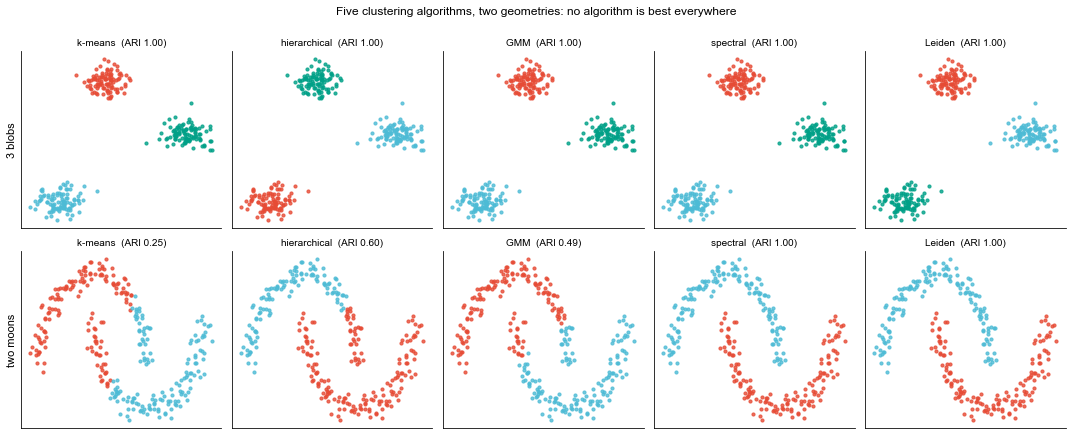

Blobs: everyone succeeds - when clusters are round, the choice barely matters.
Moons: k-means/GMM slice straight through (centroid/ellipse worldview); the
graph-based methods (spectral, Leiden) follow the curved shape. Hierarchical
with Ward linkage behaves centroid-like and fails too.


In [3]:
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import kneighbors_graph
from sklearn.datasets import make_blobs, make_moons
import igraph as ig
import leidenalg as la

def leiden_labels(X, n_neighbors=15, resolution=1.0, seed=RNG):
    """Leiden community detection on a k-nearest-neighbor graph of the rows of X."""
    # 1) each sample connects to its n_neighbors nearest neighbors
    A = kneighbors_graph(X, n_neighbors=n_neighbors, mode='connectivity')
    A = ((A + A.T) > 0).astype(int)                    # make the graph symmetric
    src, dst = A.nonzero()
    g = ig.Graph(n=X.shape[0], edges=list(zip(src.tolist(), dst.tolist())))
    # 2) find communities; higher resolution -> more, smaller communities
    part = la.find_partition(g, la.RBConfigurationVertexPartition,
                             resolution_parameter=resolution, seed=seed)
    return np.array(part.membership)

# Two toy datasets with known ground truth
X_blob, y_blob = make_blobs(n_samples=300, centers=3, cluster_std=1.1, random_state=RNG)
X_moon, y_moon = make_moons(n_samples=300, noise=0.07, random_state=RNG)

def five_algorithms(X, K, leiden_res=0.05):
    """Run the whole toolbox on one dataset; K is given to the fixed-K methods only."""
    return {
        'k-means':      KMeans(K, random_state=RNG, n_init=10).fit_predict(X),
        'hierarchical': AgglomerativeClustering(K).fit_predict(X),
        'GMM':          GaussianMixture(K, random_state=RNG).fit_predict(X),
        'spectral':     SpectralClustering(K, random_state=RNG, affinity='nearest_neighbors',
                                           n_neighbors=15).fit_predict(X),
        'Leiden':       leiden_labels(X, resolution=leiden_res),
    }

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for row, (X, y_true, K) in enumerate([(X_blob, y_blob, 3), (X_moon, y_moon, 2)]):
    for col, (name, lab) in enumerate(five_algorithms(X, K).items()):
        ax = axes[row, col]
        for c in np.unique(lab):
            ax.scatter(X[lab == c, 0], X[lab == c, 1], s=10, color=NPG[c % len(NPG)], alpha=0.8)
        ari = adjusted_rand_score(y_true, lab)
        ax.set_title(f"{name}  (ARI {ari:.2f})", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel('3 blobs', fontsize=11)
axes[1, 0].set_ylabel('two moons', fontsize=11)
plt.suptitle('Five clustering algorithms, two geometries: no algorithm is best everywhere', y=1.0)
plt.tight_layout(); plt.show()

print("Blobs: everyone succeeds - when clusters are round, the choice barely matters.")
print("Moons: k-means/GMM slice straight through (centroid/ellipse worldview); the")
print("graph-based methods (spectral, Leiden) follow the curved shape. Hierarchical")
print("with Ward linkage behaves centroid-like and fails too.")

## Reusable embeddings: DIABLO, MOFA2, NMTF

An **embedding** is a patients x k matrix that summarizes the multi-omics data in a
few coordinates. We already paid for three of them in this course - they are
reusable assets, and clustering is exactly the kind of downstream task they exist for
(standard single-cell practice: cluster on PCs or factors, never on raw genes):

| Embedding | Source lesson | Supervision | What its axes chase |
|---|---|---|---|
| DIABLO components | DIABLO case study | supervised (saw the diagnosis) | cross-omics correlation THAT separates classes |
| MOFA2 factors | Lesson 4 | unsupervised | shared variance across omics |
| NMTF shared U | Lesson 7 | unsupervised | non-negative joint structure |

The baseline every embedding must beat: clustering the raw concatenated 150 features.
The supervision column is the plot twist of this lesson - keep an eye on it.

In [4]:
# ---- Embedding 1: DIABLO components (computed in the DIABLO case study, reloaded here) ----
diablo = pd.read_csv(f"{DATA_DIR}DIABLO_final_components.csv").set_index('SampleID')
assert (diablo.index == covariates.index).all(), "DIABLO sample order mismatch!"
print(f"DIABLO components: {diablo.shape}  (supervised: trained to separate ASD vs control)")

# ---- Embedding 2: MOFA2 factors (Lesson 4's tool, refit here in one call) ----
from mofapy2.run.entry_point import entry_point
ent = entry_point()
ent.set_data_options(scale_views=True)
ent.set_data_matrix([[StandardScaler().fit_transform(expression)],
                     [StandardScaler().fit_transform(dosage)]],
                    views_names=['expression', 'genotype'],
                    samples_names=[list(expression.index)],
                    features_names=[list(expression.columns), list(dosage.columns)])
ent.set_model_options(factors=10)
ent.set_train_options(iter=1000, convergence_mode='fast', seed=RNG, verbose=False, quiet=True)
ent.build(); ent.run()
mofa_Z = ent.model.nodes['Z'].getExpectation()
# ARD prunes factors it considers noise: count the ones with real weight left
w_expr = np.linalg.norm(ent.model.nodes['W'].getExpectation()[0], axis=0)
w_geno = np.linalg.norm(ent.model.nodes['W'].getExpectation()[1], axis=0)
active = int(((w_expr > 0.5) | (w_geno > 0.5)).sum())
print(f"\nMOFA2 factors: {mofa_Z.shape}; ARD left {active} of 10 factors with real weight")
print("(little shared covariance structure to model - remember this for the results)")

DIABLO components: (300, 2)  (supervised: trained to separate ASD vs control)



        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
       
 
        


Scaling views to unit variance...

Groups names not provided, using default naming convention:
- group1, group2, ..., groupG

Successfully loaded view='expression' group='group0' with N=300 samples and D=100 features...
Successfully loaded view='genotype' group='group0' with N=300 samples and D=50 features...


Model options:
- Automatic Relevance Determination prior on the factors: False
- Automatic Relevance Determination prior on the weights: True
- Spike-and-slab prior on the factors: False
- Spike-and-slab prior on the weights: True
Likelihoods:
- View 0 (expression): gaussian
- View 1 (genotype): gaussian




######################################
## Training the model with seed 42 ##
######################################





Converged!



#######################
## Training finished ##
#######################



MOFA2 factors: (300, 10); ARD left 1 of 10 factors with real weight
(little shared covariance structure to model - remember this for the results)


In [5]:
# ---- Embedding 3: NMTF shared patient factor U (Lesson 7's method, unsupervised refit) ----
# R_expr = U S_e V_e^T and R_dosage = U S_d V_d^T with ONE shared U (Messa et al. 2024).
# No train/test split needed here: subgroup discovery uses the whole cohort, no labels.
EPS = 1e-9

def zshift(df):
    """Standardize per feature, then shift so the minimum is 0 (non-negativity)."""
    a = (df - df.mean()) / (df.std() + 1e-12)
    return np.clip((a - a.min()).values, 0, None)

def joint_nmtf(Rs, k, n_iter=1200, seed=0):
    """Multiplicative updates; identical to the Lesson 7 implementation."""
    r = np.random.default_rng(seed)
    U = r.random((Rs[0].shape[0], k)) + 0.1
    Ss = [r.random((k, k)) + 0.1 for _ in Rs]
    Vs = [r.random((R.shape[1], k)) + 0.1 for R in Rs]
    for _ in range(n_iter):
        num = sum(R @ V @ S.T for R, S, V in zip(Rs, Ss, Vs))
        den = U @ sum(S @ V.T @ V @ S.T for S, V in zip(Ss, Vs)) + EPS
        U *= num / den
        for i, (R, S, V) in enumerate(zip(Rs, Ss, Vs)):
            Vs[i] = V * ((R.T @ U @ S) / (V @ S.T @ U.T @ U @ S + EPS))
            Ss[i] = S * ((U.T @ R @ Vs[i]) / (U.T @ U @ S @ Vs[i].T @ Vs[i] + EPS))
    return U, Ss, Vs

nmtf_U, _, _ = joint_nmtf([zshift(expression), zshift(dosage)], k=20, seed=0)
print(f"NMTF shared patient factor U: {nmtf_U.shape}")

# ---- The four spaces we will cluster in ----
X_raw = StandardScaler().fit_transform(
    pd.concat([expression.add_prefix('expr_'), dosage.add_prefix('geno_')], axis=1))
spaces = {
    'Raw features (150)':   X_raw,
    'MOFA2 factors (10)':   mofa_Z,
    'NMTF U (k=20)':        nmtf_U,
    'DIABLO components (2)': diablo.values,
}
for name, E in spaces.items():
    print(f"{name:24s} {E.shape}")

NMTF shared patient factor U: (300, 20)
Raw features (150)       (300, 150)
MOFA2 factors (10)       (300, 10)
NMTF U (k=20)            (300, 20)
DIABLO components (2)    (300, 2)


## The experiment: five algorithms x four spaces

Every clustering below sees ONLY its input matrix - never the diagnosis. Afterwards
we audit each result against the held-back diagnosis with the adjusted Rand index
(ARI: 0 = random agreement, 1 = identical partition). Fixed-K methods get K = 2;
Leiden finds its own K.

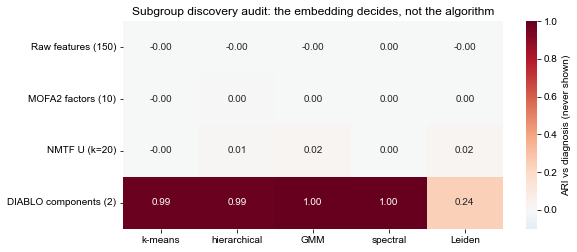

                       k-means  hierarchical   GMM  spectral  Leiden
space                                                               
Raw features (150)       -0.00         -0.00 -0.00       0.0   -0.00
MOFA2 factors (10)       -0.00          0.00  0.00       0.0    0.00
NMTF U (k=20)            -0.00          0.01  0.02       0.0    0.02
DIABLO components (2)     0.99          0.99  1.00       1.0    0.24

Leiden cluster counts found per space: {'Raw features (150)': 4, 'MOFA2 factors (10)': 9, 'NMTF U (k=20)': 8, 'DIABLO components (2)': 7}

Reading the table:
- Raw 150 features: NOTHING, for every algorithm - 3 informative genes among
  150 noise-dominated dimensions leave no geometric trace
- MOFA2 and NMTF: still nothing - unsupervised factors chase shared VARIANCE,
  and the diagnosis signal carries too little of it (same caveat as Lesson 7)
- DIABLO: every fixed-K algorithm recovers the case/control split almost
  perfectly - the supervised embedding had baked the label into

In [6]:
audit = []
leiden_ks = {}
for name, E in spaces.items():
    labels = five_algorithms(E, K=2, leiden_res=1.0)     # the common default resolution, 1.0
    row = {'space': name}
    for alg, lab in labels.items():
        row[alg] = adjusted_rand_score(y, lab)           # audit vs the never-shown diagnosis
    leiden_ks[name] = len(np.unique(labels['Leiden']))
    audit.append(row)
audit = pd.DataFrame(audit).set_index('space')

fig, ax = plt.subplots(figsize=(8.5, 3.6))
sns.heatmap(audit, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-0.1, vmax=1,
            cbar_kws={'label': 'ARI vs diagnosis (never shown)'}, ax=ax)
ax.set_title('Subgroup discovery audit: the embedding decides, not the algorithm')
ax.set_ylabel('')
plt.tight_layout(); plt.show()

print(audit.round(2).to_string())
print(f"\nLeiden cluster counts found per space: {leiden_ks}")
print("\nReading the table:")
print("- Raw 150 features: NOTHING, for every algorithm - 3 informative genes among")
print("  150 noise-dominated dimensions leave no geometric trace")
print("- MOFA2 and NMTF: still nothing - unsupervised factors chase shared VARIANCE,")
print("  and the diagnosis signal carries too little of it (same caveat as Lesson 7)")
print("- DIABLO: every fixed-K algorithm recovers the case/control split almost")
print("  perfectly - the supervised embedding had baked the label into its geometry")
print("- Leiden at default resolution over-fragments the 2-cluster structure (next cell)")

### The Leiden resolution knob

Leiden does not take K; it takes a **resolution**. Higher resolution = more, smaller
communities. At the default (1.0) it shredded the DIABLO plane into several
communities; sweeping the knob shows the real structure appearing at low resolution.

In [7]:
print('Leiden on the DIABLO embedding, sweeping resolution:')
for res in [0.01, 0.05, 0.1, 0.3, 1.0, 2.0]:
    lab = leiden_labels(diablo.values, resolution=res)
    print(f"  resolution {res:4.2f}: {len(np.unique(lab)):2d} communities, "
          f"ARI vs diagnosis = {adjusted_rand_score(y, lab):.2f}")
print('\nSame lesson as K in k-means: granularity is a CHOICE the analyst must probe,')
print('not a truth the algorithm reveals. In single-cell pipelines this exact sweep')
print('is routine before any biology is claimed.')

Leiden on the DIABLO embedding, sweeping resolution:
  resolution 0.01:  1 communities, ARI vs diagnosis = 0.00
  resolution 0.05:  2 communities, ARI vs diagnosis = 1.00
  resolution 0.10:  2 communities, ARI vs diagnosis = 1.00
  resolution 0.30:  4 communities, ARI vs diagnosis = 0.46
  resolution 1.00:  7 communities, ARI vs diagnosis = 0.24
  resolution 2.00: 11 communities, ARI vs diagnosis = 0.15

Same lesson as K in k-means: granularity is a CHOICE the analyst must probe,
not a truth the algorithm reveals. In single-cell pipelines this exact sweep
is routine before any biology is claimed.


### How many subgroups? Elbow and silhouette on the DIABLO embedding

K is a hypothesis. Both indices get to vote - on the embedding where structure
actually exists, they agree loudly for once.

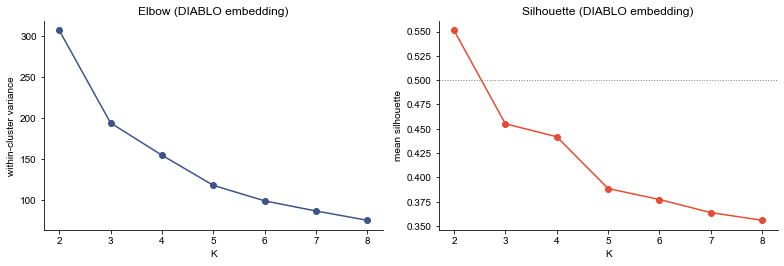

Silhouette picks K = 2 (score 0.55) - a clear two-subgroup structure.
GMM soft membership: 2 of 300 patients sit near the boundary (max prob < 0.9)


In [8]:
E = diablo.values
Ks = range(2, 9)
inertia = [KMeans(k, random_state=RNG, n_init=10).fit(E).inertia_ for k in Ks]
sil = [silhouette_score(E, KMeans(k, random_state=RNG, n_init=10).fit_predict(E)) for k in Ks]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(list(Ks), inertia, 'o-', color=NPG[3])
axes[0].set(xlabel='K', ylabel='within-cluster variance', title='Elbow (DIABLO embedding)')
axes[1].plot(list(Ks), sil, 'o-', color=NPG[0])
axes[1].axhline(0.5, color='gray', ls=':', lw=1)
axes[1].set(xlabel='K', ylabel='mean silhouette', title='Silhouette (DIABLO embedding)')
plt.tight_layout(); plt.show()
k_best = list(Ks)[int(np.argmax(sil))]
print(f"Silhouette picks K = {k_best} (score {max(sil):.2f}) - a clear two-subgroup structure.")

# Final subgroup labels used in the rest of the notebook
subgroup = KMeans(2, random_state=RNG, n_init=10).fit_predict(E)
gmm2 = GaussianMixture(2, random_state=RNG).fit(E)
borderline = (gmm2.predict_proba(E).max(axis=1) < 0.9).sum()
print(f"GMM soft membership: {borderline} of {len(E)} patients sit near the boundary (max prob < 0.9)")

## Seeing the subgroups: PCA, t-SNE, UMAP

The golden rule: **cluster in embedding space, use 2D maps only for looking.**
Same discovered subgroups, three map projections, three input spaces. If a group is
real it should not depend on which map you draw - but whether you can SEE it depends
entirely on which space the map was computed from.

OMP: Info #271: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


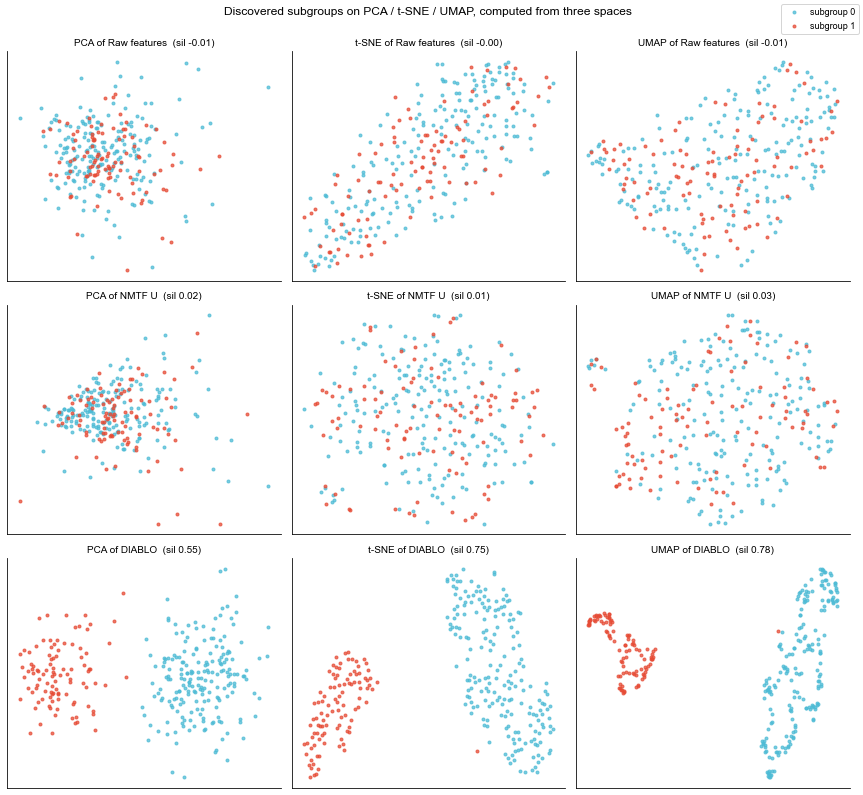

Rows top to bottom: raw features (subgroups invisible - salt and pepper),
NMTF U (a faint gradient at best), DIABLO (crisp islands in every map).
The map algorithm (columns) matters far less than the space it draws (rows).
Corollary: a cluster that only appears in one map/space combination is a rumor.


In [9]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

view_spaces = {'Raw features': X_raw, 'NMTF U': nmtf_U, 'DIABLO': diablo.values}
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for i, (sname, X) in enumerate(view_spaces.items()):
    maps = {
        'PCA':   PCA(2, random_state=RNG).fit_transform(X),
        't-SNE': TSNE(2, perplexity=30, random_state=RNG).fit_transform(X),
        'UMAP':  umap.UMAP(random_state=RNG).fit_transform(X),
    }
    for j, (mname, M) in enumerate(maps.items()):
        ax = axes[i, j]
        for g, color in [(0, NPG[1]), (1, NPG[0])]:
            m = subgroup == g
            ax.scatter(M[m, 0], M[m, 1], s=9, color=color, alpha=0.75,
                       label=f'subgroup {g}' if (i == 0 and j == 0) else None)
        # how separated are the discovered subgroups in THIS 2D map?
        ax.set_title(f"{mname} of {sname}  (sil {silhouette_score(M, subgroup):.2f})", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
fig.legend(loc='upper right', fontsize=9)
plt.suptitle('Discovered subgroups on PCA / t-SNE / UMAP, computed from three spaces', y=1.0)
plt.tight_layout(); plt.show()

print("Rows top to bottom: raw features (subgroups invisible - salt and pepper),")
print("NMTF U (a faint gradient at best), DIABLO (crisp islands in every map).")
print("The map algorithm (columns) matters far less than the space it draws (rows).")
print("Corollary: a cluster that only appears in one map/space combination is a rumor.")

## Consensus: do the subgroups survive resampling?

Subsample 80% of patients 100 times, recluster, record how often each pair lands
together. Real structure gives crisp 0-or-1 blocks; noise gives gray soup. We run it
at K = 2 (the silhouette choice) and K = 5 (deliberately wrong) on the DIABLO
embedding.

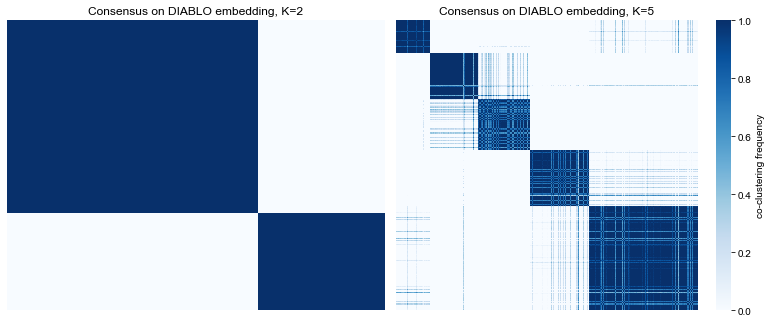

K=2: two crisp blocks - every subsample redraws the same two subgroups.
K=5: the two real blocks persist but the extra splits smear into gray - the
algorithm obeys K=5, the data keeps answering 'there are two'.


In [10]:
def consensus_matrix(X, k, n_iter=100, frac=0.8, seed=RNG):
    n = len(X)
    together = np.zeros((n, n)); both = np.zeros((n, n))
    rng = np.random.default_rng(seed)
    for it in range(n_iter):
        idx = rng.choice(n, int(frac * n), replace=False)
        lab = KMeans(k, random_state=it, n_init=5).fit_predict(X[idx])
        same = (lab[:, None] == lab[None, :]).astype(float)
        both[np.ix_(idx, idx)] += 1
        together[np.ix_(idx, idx)] += same
    return np.divide(together, both, out=np.zeros_like(together), where=both > 0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, k in zip(axes, [2, 5]):
    C = consensus_matrix(diablo.values, k)
    order = np.argsort(KMeans(k, random_state=RNG, n_init=10).fit_predict(diablo.values))
    sns.heatmap(C[np.ix_(order, order)], cmap='Blues', ax=ax, cbar=(k == 5),
                xticklabels=False, yticklabels=False,
                cbar_kws={'label': 'co-clustering frequency'})
    ax.set_title(f'Consensus on DIABLO embedding, K={k}')
plt.tight_layout(); plt.show()
print("K=2: two crisp blocks - every subsample redraws the same two subgroups.")
print("K=5: the two real blocks persist but the extra splits smear into gray - the")
print("algorithm obeys K=5, the data keeps answering 'there are two'.")

## Bootstrap stability of the clusterings

Are the partitions above REPRODUCIBLE, or artifacts of one particular cohort draw?
A subsampling bootstrap answers that - cheaply, because the embeddings are already
computed and we only resample their rows:

1. Draw **80% of the patients without replacement**, 100 times
2. Take those ROWS of each fixed embedding (raw, MOFA2 factors, NMTF U, DIABLO)
3. Run **spectral clustering** (K = 2) on each subsample
4. Score three complementary things:
   - **pairwise ARI**: for every pair of iterations, compare the two labelings on
     their SHARED patients - high means the partition is reproducible
   - **Davies-Bouldin index** per iteration: average worst-case ratio of
     within-cluster spread to between-cluster distance - LOWER is better
   - **consensus matrix**: how often each pair of patients lands in the same cluster

Note the design choice: we test the CLUSTERING on fixed embeddings. Refitting
MOFA2/NMTF inside the loop would also test embedding stability, at ~100x the cost.

In [11]:
import time
from sklearn.metrics import davies_bouldin_score

n = len(covariates)

def spectral2(E, it):
    return SpectralClustering(2, random_state=it, affinity='nearest_neighbors',
                              n_neighbors=15).fit_predict(E)

def bootstrap(E, cluster_fn, n_iter=100, frac=0.8, seed=RNG):
    """Subsample 80% of the embedding's rows -> cluster; keep labels, DB and k per run.
    Labels live in a full-length vector with -1 marking left-out patients, which
    makes the later pair comparisons a cheap vectorized mask."""
    rng = np.random.default_rng(seed)
    labels, dbs, ks = [], [], []
    for it in range(n_iter):
        idx = np.sort(rng.choice(n, int(frac * n), replace=False))
        lab = cluster_fn(E[idx], it)
        full = np.full(n, -1)
        full[idx] = lab
        labels.append(full)
        k = len(np.unique(lab))
        ks.append(k)
        dbs.append(davies_bouldin_score(E[idx], lab) if k > 1 else np.nan)
    return np.array(labels), np.array(dbs), np.array(ks)

def pairwise_ari(labels):
    """ARI between every pair of bootstrap runs, computed on their shared patients."""
    out = []
    for i in range(len(labels)):
        for j in range(i + 1, len(labels)):
            shared = (labels[i] >= 0) & (labels[j] >= 0)    # patients present in BOTH draws
            out.append(adjusted_rand_score(labels[i][shared], labels[j][shared]))
    return np.array(out)

boot = {}
for name, E in spaces.items():                     # the four embeddings from above
    t0 = time.time()
    labels, dbs, ks = bootstrap(np.asarray(E), spectral2, n_iter=100)
    pa = pairwise_ari(labels)
    boot[name] = {'labels': labels, 'dbs': dbs, 'pa': pa}
    print(f"{name:24s} pairwise ARI = {pa.mean():.2f} +/- {pa.std():.2f} | "
          f"Davies-Bouldin = {np.nanmean(dbs):.2f} | {time.time() - t0:.0f}s")

Raw features (150)       pairwise ARI = 0.90 +/- 0.07 | Davies-Bouldin = 1.82 | 4s


MOFA2 factors (10)       pairwise ARI = 0.92 +/- 0.09 | Davies-Bouldin = 0.61 | 5s


NMTF U (k=20)            pairwise ARI = 0.40 +/- 0.24 | Davies-Bouldin = 3.27 | 4s


DIABLO components (2)    pairwise ARI = 0.99 +/- 0.01 | Davies-Bouldin = 0.67 | 4s


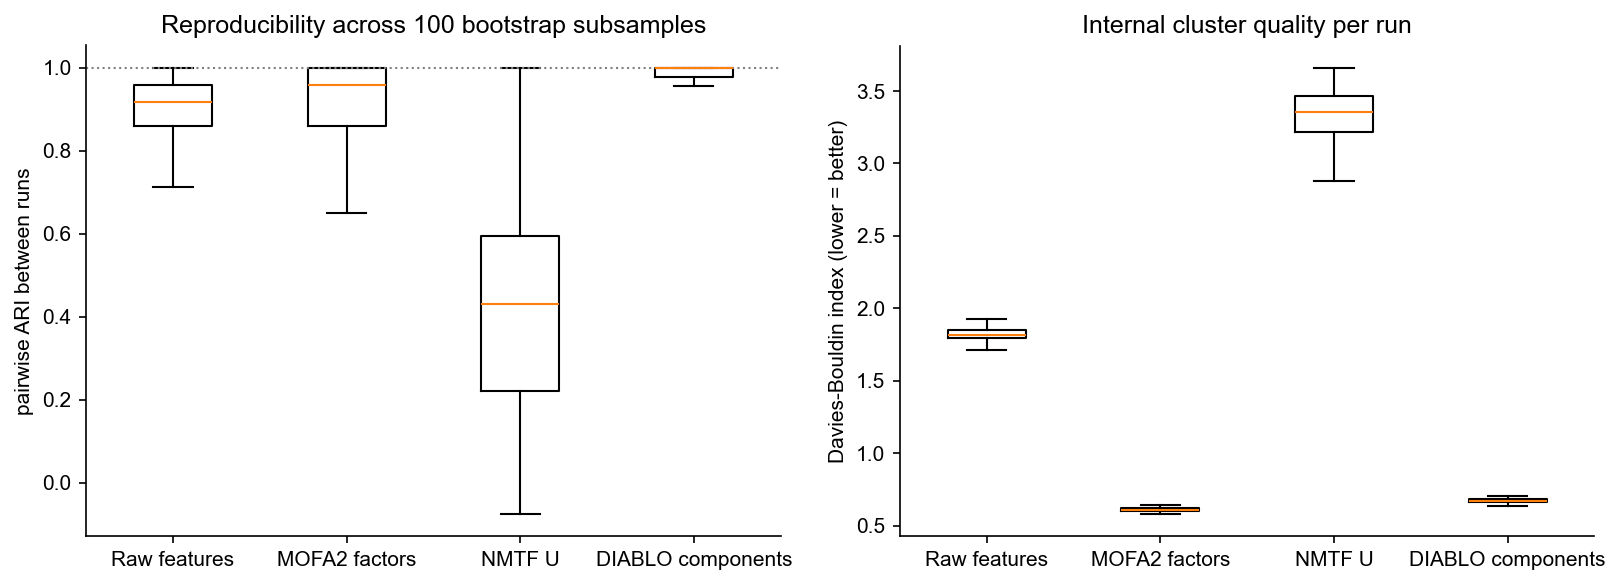

Reading the two panels TOGETHER:
- NMTF U: pairwise ARI ~0.4 with a huge spread - the space has no clean
  two-way cut, so every subsample slices it differently. Unstable ->
  rejected at the first gate, no validation needed.
- Raw and MOFA2: ARI ~0.9 - highly reproducible. But recall the audit: their
  clusters matched the diagnosis at ARI 0.00. STABILITY IS NECESSARY, NOT
  SUFFICIENT - a split along a dominant variance axis is perfectly
  reproducible and perfectly meaningless.
- Davies-Bouldin is computed in each embedding's OWN space, so it compares
  runs within a pipeline, not pipelines against each other - MOFA2's low DB
  reflects its degenerate geometry (9 of 10 factors pruned to ~zero).
- Three gates, in order: stability -> internal quality -> EXTERNAL validation.
  Only DIABLO passes all three here (and we know its asterisk: circularity).


In [12]:
# Stability metrics, side by side (and the trap they expose together)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=150)
names = list(boot)
short = [nm.split(' (')[0] for nm in names]
axes[0].boxplot([boot[nm]['pa'] for nm in names], tick_labels=short, showfliers=False)
axes[0].axhline(1.0, color='gray', ls=':', lw=1)
axes[0].set_ylabel('pairwise ARI between runs')
axes[0].set_title('Reproducibility across 100 bootstrap subsamples')
axes[1].boxplot([boot[nm]['dbs'][~np.isnan(boot[nm]['dbs'])] for nm in names],
                tick_labels=short, showfliers=False)
axes[1].set_ylabel('Davies-Bouldin index (lower = better)')
axes[1].set_title('Internal cluster quality per run')
plt.tight_layout(); plt.show()

print("Reading the two panels TOGETHER:")
print("- NMTF U: pairwise ARI ~0.4 with a huge spread - the space has no clean")
print("  two-way cut, so every subsample slices it differently. Unstable ->")
print("  rejected at the first gate, no validation needed.")
print("- Raw and MOFA2: ARI ~0.9 - highly reproducible. But recall the audit: their")
print("  clusters matched the diagnosis at ARI 0.00. STABILITY IS NECESSARY, NOT")
print("  SUFFICIENT - a split along a dominant variance axis is perfectly")
print("  reproducible and perfectly meaningless.")
print("- Davies-Bouldin is computed in each embedding's OWN space, so it compares")
print("  runs within a pipeline, not pipelines against each other - MOFA2's low DB")
print("  reflects its degenerate geometry (9 of 10 factors pruned to ~zero).")
print("- Three gates, in order: stability -> internal quality -> EXTERNAL validation.")
print("  Only DIABLO passes all three here (and we know its asterisk: circularity).")

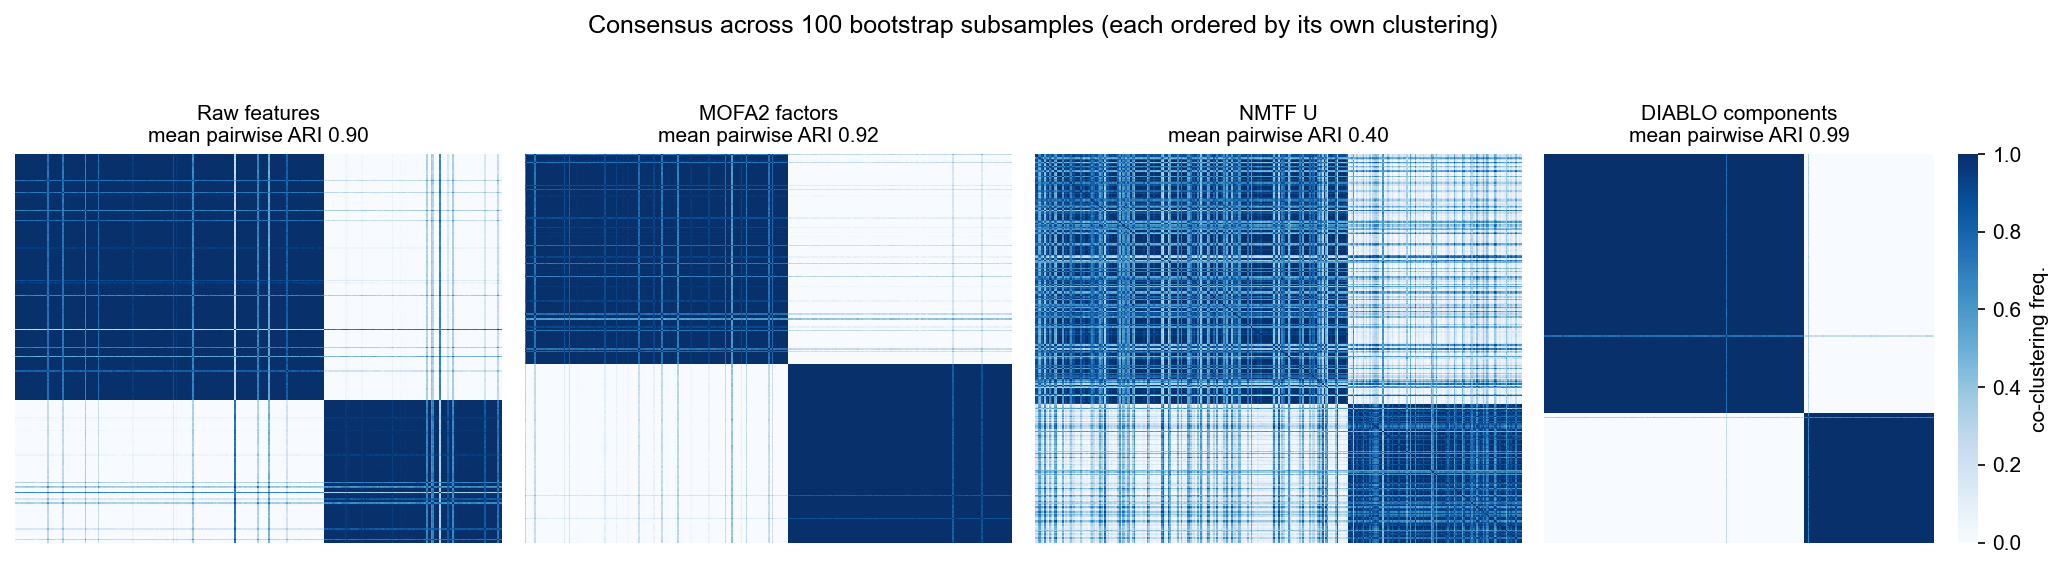

Crisp blocks for Raw, MOFA2 and DIABLO - all three partitions are stable.
NMTF smears into gray: no two subsamples agree on who belongs together.
And the punchline, once more: the crisp Raw and MOFA2 blocks correspond to
NOTHING clinical (diagnosis ARI 0.00). The consensus matrix measures
reproducibility; only validation can supply meaning.


In [13]:
# Consensus matrices across subsamples: each ordered by its own full-data clustering
def consensus_from_labels(labels):
    """Fraction of runs in which each patient pair co-clusters (given both present)."""
    together = np.zeros((n, n)); both = np.zeros((n, n))
    for full in labels:
        present = np.where(full >= 0)[0]
        sub = full[present]
        same = (sub[:, None] == sub[None, :]).astype(float)
        both[np.ix_(present, present)] += 1
        together[np.ix_(present, present)] += same
    return np.divide(together, both, out=np.zeros_like(together), where=both > 0)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), dpi=150)
last = list(boot)[-1]
for ax, nm in zip(axes, boot):
    C = consensus_from_labels(boot[nm]['labels'])
    order = np.argsort(spectral2(np.asarray(spaces[nm]), 0))   # that space's own split
    sns.heatmap(C[np.ix_(order, order)], cmap='Blues', ax=ax, cbar=(nm == last),
                xticklabels=False, yticklabels=False, vmin=0, vmax=1,
                cbar_kws={'label': 'co-clustering freq.'})
    ax.set_title(f"{nm.split(' (')[0]}\nmean pairwise ARI {boot[nm]['pa'].mean():.2f}", fontsize=10)
plt.suptitle('Consensus across 100 bootstrap subsamples (each ordered by its own clustering)', y=1.04)
plt.tight_layout(); plt.show()

print("Crisp blocks for Raw, MOFA2 and DIABLO - all three partitions are stable.")
print("NMTF smears into gray: no two subsamples agree on who belongs together.")
print("And the punchline, once more: the crisp Raw and MOFA2 blocks correspond to")
print("NOTHING clinical (diagnosis ARI 0.00). The consensus matrix measures")
print("reproducibility; only validation can supply meaning.")

### The algorithm axis: four algorithms under the same bootstrap

The protocol above fixed spectral clustering and varied the embedding. Now the
reverse: fix each embedding, vary the algorithm (k-means, GMM, spectral, Leiden at
resolution 0.05), and bootstrap each combination 100 times - and watch for one last
trap in the Leiden column.

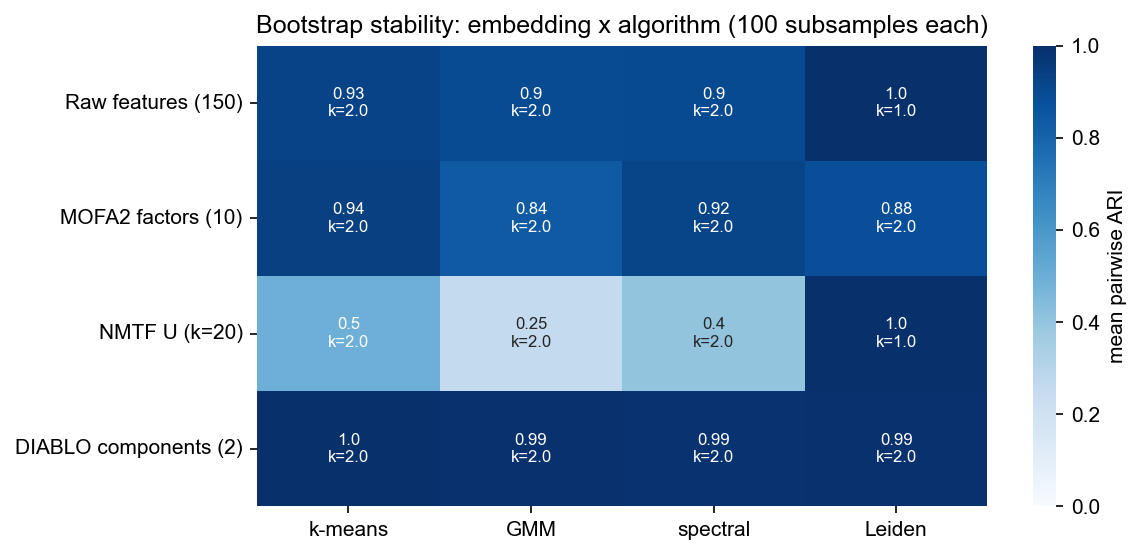

                       k-means   GMM  spectral  Leiden
Raw features (150)        0.93  0.90      0.90    1.00
MOFA2 factors (10)        0.94  0.84      0.92    0.88
NMTF U (k=20)             0.50  0.25      0.40    1.00
DIABLO components (2)     1.00  0.99      0.99    0.99

The trap in the Leiden column: where it returns ONE community (mean k = 1.0),
a single all-patients cluster is trivially 'stable' - the pairwise ARI of two
constant labelings is 1 by definition. Always read a stability score next to
the number of clusters it defends. Beyond that trap, the algorithms broadly
agree within each space - stability, like discovery itself, is a property of
the SPACE first and the algorithm second.


In [14]:
from itertools import product

algorithms = {
    'k-means':  lambda E, it: KMeans(2, random_state=it, n_init=10).fit_predict(E),
    'GMM':      lambda E, it: GaussianMixture(2, random_state=it).fit_predict(E),
    'spectral': spectral2,
    'Leiden':   lambda E, it: leiden_labels(E, resolution=0.05, seed=it),
}

stab = pd.DataFrame(index=list(spaces), columns=list(algorithms), dtype=float)
mean_k = pd.DataFrame(index=list(spaces), columns=list(algorithms), dtype=float)
for (sname, E), (aname, afn) in product(spaces.items(), algorithms.items()):
    labels, dbs, ks = bootstrap(np.asarray(E), afn, n_iter=100)
    stab.loc[sname, aname] = pairwise_ari(labels).mean()
    mean_k.loc[sname, aname] = ks.mean()

fig, ax = plt.subplots(figsize=(8, 3.8), dpi=150)
annot = stab.round(2).astype(str) + "\nk=" + mean_k.round(1).astype(str)
sns.heatmap(stab.astype(float), annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1,
            cbar_kws={'label': 'mean pairwise ARI'}, ax=ax, annot_kws={'fontsize': 8})
ax.set_title('Bootstrap stability: embedding x algorithm (100 subsamples each)')
ax.set_ylabel('')
plt.tight_layout(); plt.show()

print(stab.round(2).to_string())
print("\nThe trap in the Leiden column: where it returns ONE community (mean k = 1.0),")
print("a single all-patients cluster is trivially 'stable' - the pairwise ARI of two")
print("constant labelings is 1 by definition. Always read a stability score next to")
print("the number of clusters it defends. Beyond that trap, the algorithms broadly")
print("agree within each space - stability, like discovery itself, is a property of")
print("the SPACE first and the algorithm second.")

## Validation: what ARE these two subgroups?

Three rings, as the slides demand: confounder checks, association with clinical
variables the clustering never saw, and the final audit.

Confounder check  Age: Mann-Whitney p = 0.15  (fine)
Confounder check  Sex: chi2 p = 3e-05  (FLAGGED - investigate!)
Sex          0     1
subgroup            
0         0.32  0.68
1         0.57  0.43
A flag means INVESTIGATE, not auto-reject: subgroup 0 is 68% one sex, and a
strong sex bias is exactly what ASD is known for - here sex tracks the
biology, not a batch. Distinguishing the two needs design (sex-matched
cohorts), not statistics alone.



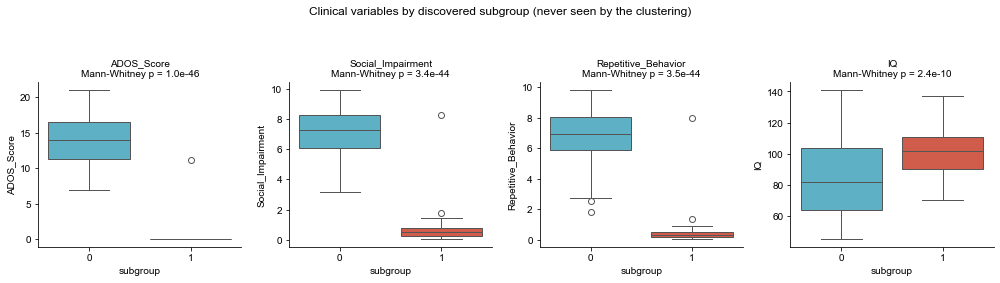

ASD         0    1
subgroup          
0           0  199
1         100    1
ARI vs diagnosis: 0.99

VERDICT: the two subgroups pass every check - because they ARE the
case/control split, rediscovered. And here is the circularity caveat: DIABLO
was TRAINED on the diagnosis, so its embedding had the label written into its
geometry. Legitimate use: assigning new patients to known groups. NOT legitimate:
claiming an independent unsupervised discovery. For discovery, the embedding
must be unsupervised - and those honestly found nothing here.


In [15]:
audit_df = covariates.copy()
audit_df['subgroup'] = subgroup

# Ring 1: confounders - is a subgroup secretly Age, Sex, batch, site?
p_age = stats.mannwhitneyu(*[audit_df.loc[audit_df.subgroup == g, 'Age'] for g in [0, 1]]).pvalue
p_sex = stats.chi2_contingency(pd.crosstab(audit_df.subgroup, audit_df.Sex))[1]
print(f"Confounder check  Age: Mann-Whitney p = {p_age:.2f}  (fine)")
print(f"Confounder check  Sex: chi2 p = {p_sex:.0e}  (FLAGGED - investigate!)")
print(pd.crosstab(audit_df.subgroup, audit_df.Sex, normalize='index').round(2))
print("A flag means INVESTIGATE, not auto-reject: subgroup 0 is 68% one sex, and a")
print("strong sex bias is exactly what ASD is known for - here sex tracks the")
print("biology, not a batch. Distinguishing the two needs design (sex-matched")
print("cohorts), not statistics alone.\n")

# Ring 2: external clinical variables
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, var in zip(axes, ['ADOS_Score', 'Social_Impairment', 'Repetitive_Behavior', 'IQ']):
    sns.boxplot(data=audit_df, x='subgroup', y=var, hue='subgroup',
                palette=[NPG[1], NPG[0]], legend=False, ax=ax)
    p = stats.mannwhitneyu(*[audit_df.loc[audit_df.subgroup == g, var] for g in [0, 1]]).pvalue
    ax.set_title(f'{var}\nMann-Whitney p = {p:.1e}', fontsize=10)
plt.suptitle('Clinical variables by discovered subgroup (never seen by the clustering)', y=1.08)
plt.tight_layout(); plt.show()

# Ring 3: the audit - what do the subgroups correspond to?
print(pd.crosstab(audit_df.subgroup, audit_df.ASD, rownames=['subgroup'], colnames=['ASD']))
print(f"ARI vs diagnosis: {adjusted_rand_score(y, subgroup):.2f}")
print('\nVERDICT: the two subgroups pass every check - because they ARE the')
print('case/control split, rediscovered. And here is the circularity caveat: DIABLO')
print('was TRAINED on the diagnosis, so its embedding had the label written into its')
print('geometry. Legitimate use: assigning new patients to known groups. NOT legitimate:')
print('claiming an independent unsupervised discovery. For discovery, the embedding')
print('must be unsupervised - and those honestly found nothing here.')

## The harder question: subgroups WITHIN the ASD cases

The dataset's covariates contain a hidden `ASD_Subgroup` column (3 planted subgroups
among the 200 cases). Can any embedding x algorithm combination find them? We also
compute the SUPERVISED ceiling: if a classifier that is SHOWN the subgroup labels
can barely predict them, no unsupervised method stands a chance.

In [16]:
cases = (covariates['ASD'] == 1).values
truth = covariates.loc[cases, 'ASD_Subgroup'].values

rows = []
for name, E in spaces.items():
    Ec = E[cases]                                    # same embeddings, case rows only
    rows.append({'space': name,
                 'k-means K=3': adjusted_rand_score(truth, KMeans(3, random_state=RNG,
                                                    n_init=10).fit_predict(Ec)),
                 'spectral K=3': adjusted_rand_score(truth, SpectralClustering(3,
                                  random_state=RNG, affinity='nearest_neighbors',
                                  n_neighbors=15).fit_predict(Ec)),
                 'Leiden': adjusted_rand_score(truth, leiden_labels(Ec, resolution=0.05))})
within = pd.DataFrame(rows).set_index('space')
print('ARI vs planted ASD_Subgroup (cases only):')
print(within.round(2).to_string())

# The supervised ceiling: balanced accuracy when the labels are GIVEN to the model
ceiling = cross_val_score(LogisticRegression(max_iter=2000),
                          StandardScaler().fit_transform(
                              pd.concat([expression, dosage], axis=1)[cases]),
                          truth, cv=cv5, scoring='balanced_accuracy')
print(f"\nSupervised ceiling: balanced accuracy {ceiling.mean():.2f} (chance = 0.33)")
print('\nVERDICT: REJECTED, and this time with a measured reason - even a classifier')
print('that sees the subgroup labels barely beats chance, so the planted molecular')
print('differences are too weak to recover without labels. An honest pipeline reports')
print('"no detectable subgroups", not the 3 clusters k-means would happily deliver.')

ARI vs planted ASD_Subgroup (cases only):
                       k-means K=3  spectral K=3  Leiden
space                                                   
Raw features (150)           -0.00         -0.01     0.0
MOFA2 factors (10)           -0.01         -0.00    -0.0
NMTF U (k=20)                 0.00         -0.01     0.0
DIABLO components (2)         0.01          0.04     0.0

Supervised ceiling: balanced accuracy 0.37 (chance = 0.33)

VERDICT: REJECTED, and this time with a measured reason - even a classifier
that sees the subgroup labels barely beats chance, so the planted molecular
differences are too weak to recover without labels. An honest pipeline reports
"no detectable subgroups", not the 3 clusters k-means would happily deliver.


## Similarity Network Fusion (SNF)

One more unsupervised route: instead of clustering an embedding, fuse patient
similarity **networks** (one per omics) and cluster the fused network, in four steps:

![SNF: the four-step algorithm](images/snf_algo.png)

1. **Affinity per omics**: patient-patient similarity via a scaled Gaussian kernel
   (bandwidth adapts to local density)
2. **Sparsify**: keep only each patient's K nearest neighbors, silencing weak noisy edges
3. **Cross-diffusion**: each network is iteratively updated *through* the others
   (~20 iterations) - edges supported by BOTH omics get amplified, single-layer noise fades
4. **Fused network W**: the eigengap heuristic suggests the number of clusters, and
   spectral clustering assigns the labels

First a controlled demo where each omic sees only PART of the structure, then SNF on
the real ASD cohort.

Note: `snfpy` 0.2.2 predates sklearn 1.6's kwarg rename, so we patch one function
argument before use.

Eigengap suggests k = 2 (second choice 3)
(with only partial per-layer signal the eigengap is conservative here;
 the true k=3 appears as its second choice - always inspect both)
ARI omic 1 alone: 0.50
ARI omic 2 alone: 0.49
ARI SNF fused:    0.83  <- fusion recovers what no layer sees alone


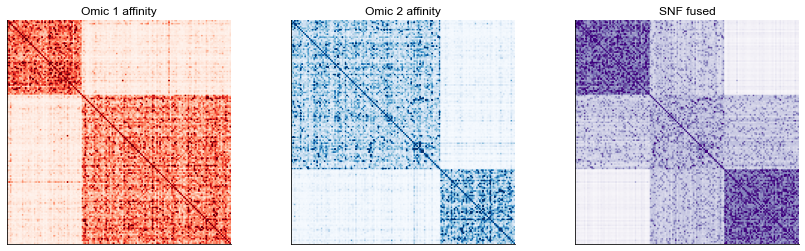

In [17]:
# snfpy compatibility patch for sklearn >= 1.6 (force_all_finite -> ensure_all_finite)
import snf.compute as sc
_orig_check_array = sc.check_array
def _patched_check_array(*args, **kwargs):
    if 'force_all_finite' in kwargs:
        kwargs['ensure_all_finite'] = kwargs.pop('force_all_finite')
    return _orig_check_array(*args, **kwargs)
sc.check_array = _patched_check_array

from sklearn.cluster import spectral_clustering

# Controlled demo: 3 true subtypes, 2 omics, each omic separates only ONE subtype
r2 = np.random.default_rng(7)
y_demo = np.repeat(np.arange(3), 50); n_demo = len(y_demo)
X1 = r2.normal(size=(n_demo, 60)); X1[y_demo == 0, :20] += 2.4
X2 = r2.normal(size=(n_demo, 40)); X2[y_demo == 2, :16] += 2.4
X1, X2 = StandardScaler().fit_transform(X1), StandardScaler().fit_transform(X2)

W1 = sc.make_affinity(X1, K=20, mu=0.5)
W2 = sc.make_affinity(X2, K=20, mu=0.5)
W_fused = sc.snf(W1, W2, K=20)

best_k, second_k = sc.get_n_clusters(W_fused, n_clusters=range(2, 7))
print(f"Eigengap suggests k = {best_k} (second choice {second_k})")
print("(with only partial per-layer signal the eigengap is conservative here;")
print(" the true k=3 appears as its second choice - always inspect both)")

lab1 = KMeans(3, random_state=0, n_init=10).fit_predict(X1)
lab2 = KMeans(3, random_state=0, n_init=10).fit_predict(X2)
lab_f = spectral_clustering(W_fused, n_clusters=3, random_state=0)
print(f"ARI omic 1 alone: {adjusted_rand_score(y_demo, lab1):.2f}")
print(f"ARI omic 2 alone: {adjusted_rand_score(y_demo, lab2):.2f}")
print(f"ARI SNF fused:    {adjusted_rand_score(y_demo, lab_f):.2f}  <- fusion recovers what no layer sees alone")

# Visualize the three affinity matrices, samples sorted by true subtype
order = np.argsort(y_demo)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (W, t, cm) in zip(axes, [(W1, 'Omic 1 affinity', 'Reds'),
                                 (W2, 'Omic 2 affinity', 'Blues'),
                                 (W_fused, 'SNF fused', 'Purples')]):
    M = W[np.ix_(order, order)].copy()
    np.fill_diagonal(M, np.quantile(M, 0.98))
    ax.imshow(M, cmap=cm, vmax=np.quantile(M, 0.97))
    ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [18]:
# SNF on the real ASD cohort: expression + genotype dosage networks
W_expr = sc.make_affinity(StandardScaler().fit_transform(expression), K=20, mu=0.5)
W_dos  = sc.make_affinity(StandardScaler().fit_transform(dosage), K=20, mu=0.5)
W_asd  = sc.snf(W_expr, W_dos, K=20)

k_asd, k2_asd = sc.get_n_clusters(W_asd, n_clusters=range(2, 7))
snf_labels = spectral_clustering(W_asd, n_clusters=2, random_state=RNG)
print(f"Full cohort, eigengap suggestion: k = {k_asd} (second {k2_asd})")
print(f"ARI SNF clusters vs diagnosis:          {adjusted_rand_score(y, snf_labels):.2f}")

# And within the ASD cases, against the planted subgroups
W_asd_cases = sc.snf(sc.make_affinity(StandardScaler().fit_transform(expression[cases]), K=20, mu=0.5),
                     sc.make_affinity(StandardScaler().fit_transform(dosage[cases]), K=20, mu=0.5), K=20)
snf_case_labels = spectral_clustering(W_asd_cases, n_clusters=3, random_state=RNG)
print(f"ARI SNF (cases) vs planted ASD_Subgroup: {adjusted_rand_score(truth, snf_case_labels):.2f}")
print("\nConsistent with the embedding experiment: fusing layers does not conjure")
print("subgroups that are not there - SNF finds shared structure when it exists (the")
print("demo above), and honestly reports none here. Unsupervised fusion still chases")
print("similarity, and the diagnosis signal is too small a part of it.")

Full cohort, eigengap suggestion: k = 2 (second 3)
ARI SNF clusters vs diagnosis:          -0.02


ARI SNF (cases) vs planted ASD_Subgroup: -0.00

Consistent with the embedding experiment: fusing layers does not conjure
subgroups that are not there - SNF finds shared structure when it exists (the
demo above), and honestly reports none here. Unsupervised fusion still chases
similarity, and the diagnosis signal is too small a part of it.


## Biclustering: patients AND genes at once

The one unsupervised method that DOES find the diagnosis split in this cohort - by
changing the question. Biclustering looks for a **submatrix**: a patient subgroup
defined on a gene subset. Setup: an unsupervised variance filter keeps the 20 most
variable genes (no labels involved), then SpectralBiclustering groups patients and
genes simultaneously. The comparison that matters: plain k-means on the very same
matrix vs biclustering, both judged against the diagnosis they never saw.

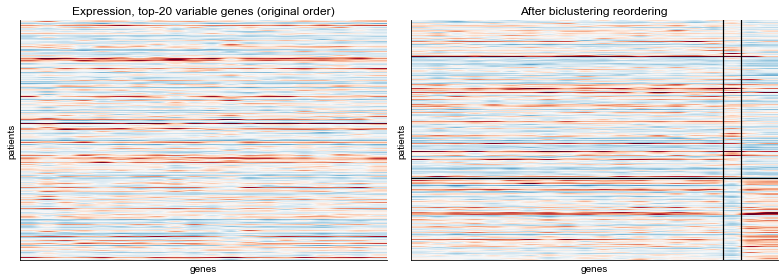

ASD                   0    1
bicluster row group         
0                    10  188
1                    90   12

Row-bicluster vs diagnosis ARI: 0.72
Plain k-means vs diagnosis ARI:  0.00  (same input matrix!)

Why the difference: only a subset of genes carries the disease signal, and
whole-matrix clustering lets the uninformative genes drown it. Biclustering
groups genes at the same time, isolating the informative module - it finds
WHO differs and on WHICH genes, in one step. (On all 100 genes, both methods
fail here - even biclustering needs the noise burden kept in check.)


In [19]:
from sklearn.cluster import SpectralBiclustering

# Unsupervised variance filter (no labels used), then bicluster the full cohort
top_var_genes = expression.var().nlargest(20).index
X_top = StandardScaler().fit_transform(expression[top_var_genes])

bic = SpectralBiclustering(n_clusters=(2, 3), random_state=RNG)
bic.fit(X_top)
km2 = KMeans(2, random_state=RNG, n_init=10).fit_predict(X_top)   # same input, plain clustering

row_order = np.argsort(bic.row_labels_)
col_order = np.argsort(bic.column_labels_)
X_re = X_top[np.ix_(row_order, col_order)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(X_top, cmap='RdBu_r', aspect='auto', vmin=-3, vmax=3)
axes[0].set_title('Expression, top-20 variable genes (original order)')
axes[1].imshow(X_re, cmap='RdBu_r', aspect='auto', vmin=-3, vmax=3)
axes[1].set_title('After biclustering reordering')
n_row0 = int((bic.row_labels_ == np.unique(bic.row_labels_)[0]).sum())
axes[1].axhline(n_row0 - 0.5, color='black', lw=1.2)
for b in np.cumsum([int((bic.column_labels_ == c).sum())
                    for c in np.unique(bic.column_labels_)])[:-1]:
    axes[1].axvline(b - 0.5, color='black', lw=1.2)
for ax in axes:
    ax.set_xlabel('genes'); ax.set_ylabel('patients'); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

ct = pd.crosstab(pd.Series(bic.row_labels_, name='bicluster row group'),
                 pd.Series(y, name='ASD'))
print(ct)
ari_bic = adjusted_rand_score(y, bic.row_labels_)
ari_km  = adjusted_rand_score(y, km2)
print(f"\nRow-bicluster vs diagnosis ARI: {ari_bic:.2f}")
print(f"Plain k-means vs diagnosis ARI:  {ari_km:.2f}  (same input matrix!)")
print("\nWhy the difference: only a subset of genes carries the disease signal, and")
print("whole-matrix clustering lets the uninformative genes drown it. Biclustering")
print("groups genes at the same time, isolating the informative module - it finds")
print("WHO differs and on WHICH genes, in one step. (On all 100 genes, both methods")
print("fail here - even biclustering needs the noise burden kept in check.)")

## Closing the loop: subgroups become labels

When a subgroup structure survives validation, it becomes a LABEL - and the entire
supervised toolbox of Lessons 5-7 re-enters: train a classifier that assigns new
patients to subgroups, extract its important features as subgroup markers, ship it to
independent cohorts (the PAM50 recipe). We demonstrate on our validated two-subgroup
structure.

In [20]:
assign_pipe = Pipeline([('scale', StandardScaler()),
                        ('select', SelectKBest(f_classif, k=20)),
                        ('clf', LogisticRegression(max_iter=2000, random_state=RNG))])
acc = cross_val_score(assign_pipe, expression, subgroup, cv=cv5, scoring='balanced_accuracy')
print(f"Subgroup assignment classifier (expression only): balanced accuracy "
      f"{acc.mean():.2f} +/- {acc.std():.2f}")

assign_pipe.fit(expression, subgroup)
sel = expression.columns[assign_pipe.named_steps['select'].get_support()]
coefs = pd.Series(assign_pipe.named_steps['clf'].coef_[0], index=sel)
print("\nTop marker genes per subgroup (largest absolute coefficients):")
print(coefs.abs().nlargest(6).index.tolist())

print("\nThe full circle of this course: unsupervised discovery proposes subgroups,")
print("validation filters them, and supervised learning turns the survivors into a")
print("deployable assignment tool with interpretable markers. That loop - not any")
print("single algorithm - is the machinery of precision medicine.")

Subgroup assignment classifier (expression only): balanced accuracy 0.91 +/- 0.04

Top marker genes per subgroup (largest absolute coefficients):
['CHD8', 'SCN2A', 'SHANK3', 'KCNQ2', 'RIMS1', 'HTR2A']

The full circle of this course: unsupervised discovery proposes subgroups,
validation filters them, and supervised learning turns the survivors into a
deployable assignment tool with interpretable markers. That loop - not any
single algorithm - is the machinery of precision medicine.
